### 🔴 Section 1: Implement for MA's

#### ⚪ 1. Libraries

In [29]:
### Cell 1
import pandas as pd
import scipy.io
import numpy as np
from scipy.io import loadmat
from sklearn.preprocessing import MinMaxScaler
from scipy.spatial.distance import cdist
from sklearn.metrics import roc_auc_score, average_precision_score

#### ⚪ 2. Extract indices from .csv file

In [30]:
# --- Configuration ---
csv_file_path = '/media/mine/Mine/3.Main-Ubuntu-Envs/2.Thesis-Env/3.Datasets/mammographyori.csv'

def get_ma_indices(df, feature_name, low, high):
    condition = (df[feature_name] >= low) & (df[feature_name] <= high)
    subset = df[condition]
    indices = subset.index.to_numpy()
    counts = subset['label'].value_counts()
    return indices, counts

df_original = pd.read_csv(csv_file_path, header=None)
df_original.columns = ['c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'label']
print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")

ma_conditions = {
    'MA1': ('c4', -0.9, 2),
    'MA2': ('c5', -0.4, 1),
    'MA3': ('c6', -1, 1),
}

ma_indices = {}
ma_label_counts = {}
for name, (feature, low, high) in ma_conditions.items():
    indices, counts = get_ma_indices(df_original, feature, low, high)
    ma_indices[name] = indices
    ma_label_counts[name] = counts
    print(f"{name} Condition: Feature '{feature}' in [{low}, {high}]")
    print(f"  samples = {len(indices)}")
    print(f"  label counts =\n{counts}\n")

Shape of the original dataset: (11183, 7) (rows, columns)
MA1 Condition: Feature 'c4' in [-0.9, 2]
  samples = 10951
  label counts =
label
1    10747
2      204
Name: count, dtype: int64

MA2 Condition: Feature 'c5' in [-0.4, 1]
  samples = 10098
  label counts =
label
1    10022
2       76
Name: count, dtype: int64

MA3 Condition: Feature 'c6' in [-1, 1]
  samples = 8263
  label counts =
label
1    8209
2      54
Name: count, dtype: int64



#### ⚪ 3. Create X_tem lists for MA1/MA2/MA3

In [31]:
X_tem_ma1 = ma_indices['MA1'].tolist()
X_tem_ma2 = ma_indices['MA2'].tolist()
X_tem_ma3 = ma_indices['MA3'].tolist()

print('MA1 size:', len(X_tem_ma1))
print('MA2 size:', len(X_tem_ma2))
print('MA3 size:', len(X_tem_ma3))

MA1 size: 10951
MA2 size: 10098
MA3 size: 8263


In [32]:
# Three-way neighborhood characteristic region-based outlier detection (3WIROD) algorithm
# Please refer to the following papers:
# Zhang Xianyong, Yuan Zhong, and Miao Duoqian.Outlier Detection Using Three-Way
# Neighborhood Characteristic Regions and Corresponding Fusion Measurement[J].TKDE,2023.
# Uploaded by Yuan Zhong on August 29, 2023. E-mail:yuanzhong2799@foxmail.com.

def WNCROD(data, X_tem, lammda):
    # input:
    # data is data matrix without decisions, where rows for samples and columns for attributes.
    # Numerical attributes should be normalized into [0,1].
    # Nominal attributes be replaced by different integer values.
    # X_tem denotes the selected condition subdata.
    # lammda is a given parameter for the radius adjustment.
    # output
    # Multiple neighborhood outlier factor (MNOF)
    n, m = data.shape
    X = np.zeros(n)
    X[X_tem] = 1

    D1 = m / 3
    D2 = m / 2
    D3 = 0.9 * m

    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    delta[ID] = np.std(data[:, ID], axis=0) / lammda

    Lower = np.zeros((m, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        Lower_temp = np.min(np.maximum(1 - RM_tem, np.tile(X, (n, 1))), axis=1)
        Lower[col, :Lower_temp.shape[0]] = Lower_temp

    IB = np.tile(X, (m, 1)) - Lower
    NEB = np.min(IB, axis=0)
    NPB = IB - np.tile(NEB, (m, 1))

    n_X = int(sum(X))

    weight = np.zeros((n_X, m))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        weight_x = []

        for i in range(n_X):
            temp1 = RM_tem[X_tem[i], :]
            weight_temp = 1 - (np.sqrt((np.sum(np.minimum(temp1, X))) / n_X))
            weight_x.append(weight_temp)

        weight[:len(weight_x), col] = weight_x

    D_tem = np.zeros((n, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        D_tem += RM_tem

    NOM = m - D_tem
    X_OM = NOM[np.ix_(X_tem, X_tem)]

    NEB_num = np.zeros((n_X, m))
    Lower_num = np.zeros((n_X, m))
    NPB_num = np.zeros((n_X, m))

    for col in range(m):
        temp2 = Lower[col, :]
        temp3 = NPB[col, :]

        for i in range(n_X):
            temp1 = X_OM[i, :]
            NEB_num[i, col] = np.sum(np.minimum(NEB[X_tem], temp1 <= D1))
            NPB_num[i, col] = np.sum(np.minimum(temp3[X_tem], temp1 >= D2))
            Lower_num[i, col] = np.sum(np.minimum(temp2[X_tem], temp1 >= D3))

    MNOF = np.mean(((NEB_num + Lower_num + NPB_num) / n_X) * weight, axis=1)
    return MNOF


#### ⚪ 4. Run WNCROD for MA1, MA2, and MA3

In [33]:
# 1) Load data and normalize once
mat = loadmat('/media/mine/Mine/3.Main-Ubuntu-Envs/2.Thesis-Env/3.Datasets/mammography.mat')
full_data = mat['trandata']            # shape = (n_samples, 7)

X = full_data[:, :6]
y = full_data[:, 6].astype(int)

scaler = MinMaxScaler()
X[:, 1:] = scaler.fit_transform(X[:, 1:])

print('Loaded and normalized data once for all MA subsets.')

def evaluate_wncrod(data, labels, X_tem, lam=0.5):
    out_scores = WNCROD(data, X_tem, lammda=lam)
    return roc_auc_score(labels[X_tem], out_scores), average_precision_score(labels[X_tem], out_scores)

print('Running WNCROD for MA1, MA2, MA3 with λ = 0.5')
for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    roc_auc, ap = evaluate_wncrod(X, y, X_tem, lam=0.5)
    print(f"{name}: ROC-AUC = {roc_auc:.4f}, AP = {ap:.4f}")


Loaded and normalized data once for all MA subsets.
Running WNCROD for MA1, MA2, MA3 with λ = 0.5
MA1: ROC-AUC = 0.8931, AP = 0.3550
MA2: ROC-AUC = 0.7745, AP = 0.0626
MA3: ROC-AUC = 0.7748, AP = 0.0827


#### ⚪ 5. Run WNCROD only on MA1 for λ = 0.1 to 2.0

In [34]:
lambda_list_ma1 = [0.1, 0.2, 0.3, 0.4, 0.5,
                   0.6, 0.7, 0.8, 0.9, 1.0,
                   1.1, 1.2, 1.3, 1.4, 1.5,
                   1.6, 1.7, 1.8, 1.9, 2.0]

ma1_results = []
for lam in lambda_list_ma1:
    roc_auc, ap = evaluate_wncrod(X, y, X_tem_ma1, lam=lam)
    ma1_results.append({'lambda': lam, 'ROC-AUC': roc_auc, 'AP': ap})

print('MA1 results for λ = 0.1 to 2.0:')
for r in ma1_results:
    print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")

MA1 results for λ = 0.1 تا 2.0:
λ = 0.1 | ROC-AUC = 0.3409 | AP = 0.0168
λ = 0.2 | ROC-AUC = 0.4595 | AP = 0.0509
λ = 0.3 | ROC-AUC = 0.6006 | AP = 0.0774
λ = 0.4 | ROC-AUC = 0.7606 | AP = 0.1505
λ = 0.5 | ROC-AUC = 0.8931 | AP = 0.3550
λ = 0.6 | ROC-AUC = 0.8874 | AP = 0.2114
λ = 0.7 | ROC-AUC = 0.8610 | AP = 0.1315
λ = 0.8 | ROC-AUC = 0.8548 | AP = 0.1018
λ = 0.9 | ROC-AUC = 0.8506 | AP = 0.0905
λ = 1.0 | ROC-AUC = 0.8448 | AP = 0.0809
λ = 1.1 | ROC-AUC = 0.8277 | AP = 0.0748
λ = 1.2 | ROC-AUC = 0.8196 | AP = 0.0685
λ = 1.3 | ROC-AUC = 0.8154 | AP = 0.0640
λ = 1.4 | ROC-AUC = 0.8082 | AP = 0.0601
λ = 1.5 | ROC-AUC = 0.8032 | AP = 0.0567
λ = 1.6 | ROC-AUC = 0.7934 | AP = 0.0530
λ = 1.7 | ROC-AUC = 0.7858 | AP = 0.0500
λ = 1.8 | ROC-AUC = 0.7787 | AP = 0.0474
λ = 1.9 | ROC-AUC = 0.7761 | AP = 0.0457
λ = 2.0 | ROC-AUC = 0.7727 | AP = 0.0442


#### ⚪ 6. Run WNCROD for All MA for λ = 0.1 to 2.0

In [ ]:
lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
               0.6, 0.7, 0.8, 0.9, 1.0,
               1.1, 1.2, 1.3, 1.4, 1.5,
               1.6, 1.7, 1.8, 1.9, 2.0]

all_results = {name: [] for name in ['MA1', 'MA2', 'MA3']}
for lam in lambda_list:
    for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
        roc_auc, ap = evaluate_wncrod(X, y, X_tem, lam=lam)
        all_results[name].append({'lambda': lam, 'ROC-AUC': roc_auc, 'AP': ap})

for name in ['MA1', 'MA2', 'MA3']:
    print(f'\n{name} results:')
    for r in all_results[name]:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")

In [ ]:
import matplotlib.pyplot as plt

lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
               0.6, 0.7, 0.8, 0.9, 1.0,
               1.1, 1.2, 1.3, 1.4, 1.5,
               1.6, 1.7, 1.8, 1.9, 2.0]

roc_auc_ma1 = [r['ROC-AUC'] for r in all_results['MA1']]

plt.figure(figsize=(8, 5))
plt.plot(lambda_list, roc_auc_ma1, marker='o', linestyle='-',
         color='C0', label='ROC-AUC')
plt.title('ROC-AUC vs λ (MA1)')
plt.xlabel('λ')
plt.ylabel('ROC-AUC')
plt.xticks(lambda_list, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 🔴 Section 2: New Idea's

#### ⚪ 0. Checking Idea's

In [35]:
### Cell 9
import importlib
from sklearn.metrics import roc_auc_score, average_precision_score

# Load module dynamically to support filenames starting with numbers (e.g., '1_opus_5_thinking')
try:
    opus_module = importlib.import_module("1_opus_5_thinking")
except ModuleNotFoundError:
    # Fallback in case the file was renamed without the leading digit
    opus_module = importlib.import_module("opus_5_thinking")

# Extract required classes and registry from the loaded module
VARIANTS = opus_module.VARIANTS
Variant0Baseline = opus_module.Variant0Baseline
Variant1AdaptiveRadius = opus_module.Variant1AdaptiveRadius
Variant2DiscriminativeWeights = opus_module.Variant2DiscriminativeWeights
Variant3SubspaceAugmented = opus_module.Variant3SubspaceAugmented
Variant4TieredEvidence = opus_module.Variant4TieredEvidence
Variant5RobustScale = opus_module.Variant5RobustScale
Variant6SilvermanSelector = opus_module.Variant6SilvermanSelector
Variant7AmiseRate = opus_module.Variant7AmiseRate
Variant8ResolutionFloor = opus_module.Variant8ResolutionFloor
VariantFull = opus_module.VariantFull

# Evaluation wrapper matching the existing pipeline interface
def evaluate_opus_model(model_cls, data, labels, X_tem, lam=0.5):
    # Initialize model (lambda is automatically ignored by parameter-free variants)
    model = model_cls(lammda=lam)
    out_scores = model.fit_predict(data, X_index=X_tem)
    auc = roc_auc_score(labels[X_tem], out_scores)
    ap = average_precision_score(labels[X_tem], out_scores)
    return auc, ap

# Sanity Check: Verify exact mathematical alignment of V0 with baseline results on MA1
v0_auc, v0_ap = evaluate_opus_model(Variant0Baseline, X, y, X_tem_ma1, lam=0.5)
print(f"[Sanity Check] V0 on MA1 (lambda=0.5): ROC-AUC = {v0_auc:.4f}, AP = {v0_ap:.4f}")

[Sanity Check] V0 on MA1 (lambda=0.5): ROC-AUC = 0.8931, AP = 0.3550


In [36]:
### Cell 10
# Variant descriptions mapping for report and logging
variant_descriptions = {
    "V0": "Baseline (Original 3WNCROD)",
    "V1": "Idea 1: Adaptive Radius (Eq. 8*) [No Lambda]",
    "V2": "Idea 2: Discriminative Weights (Eq. 10*)",
    "V3": "Idea 3: Subspace Augmentation (Alg. 0*, Eq. 9*)",
    "V4": "Idea 4: Tiered Evidence NDF (Eq. 4*)",
    "V5": "Ablation: Robust Scale Only (MADN / lambda)",
    "V6": "Ablation: Silverman Selector Only",
    "V7": "Ablation: AMISE Rate Only [No Lambda]",
    "V8": "Ablation: Resolution Floor Only (1/n)",
    "VF": "Full Enhanced (All Ideas Combined) [No Lambda]"
}

comparison_records = []
print("Evaluating all Opus 5 variants on MA1, MA2, MA3 (lambda = 0.5)...")

for key, model_cls in VARIANTS.items():
    row = {
        "Key": key,
        "Description": variant_descriptions.get(key, key)
    }
    for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
        auc, ap = evaluate_opus_model(model_cls, X, y, X_tem, lam=0.5)
        row[f"{name} AUC"] = round(auc, 4)
        row[f"{name} AP"] = round(ap, 4)
    comparison_records.append(row)

# Display tabular comparison
df_comparison = pd.DataFrame(comparison_records)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print("\n--- Performance Comparison Table (lambda = 0.5) ---")
display(df_comparison)

Evaluating all Opus 5 variants on MA1, MA2, MA3 (lambda = 0.5)...

--- Performance Comparison Table (lambda = 0.5) ---


,Key,Description,MA1 AUC,MA1 AP,MA2 AUC,MA2 AP,MA3 AUC,MA3 AP
0,V0,Baseline (Original 3WNCROD),0.8931,0.3550,0.7745,0.0626,0.7748,0.0827
1,V1,Idea 1: Adaptive Radius (Eq. 8*) [No Lambda],0.8138,0.0664,0.6871,0.0160,0.7215,0.0258
2,V2,Idea 2: Discriminative Weights (Eq. 10*),0.8086,0.2979,0.5626,0.0101,0.6450,0.0155
3,V3,"Idea 3: Subspace Augmentation (Alg. 0*, Eq. 9*)",0.8927,0.3718,0.7382,0.0363,0.6744,0.0180
4,V4,Idea 4: Tiered Evidence NDF (Eq. 4*),0.8928,0.3556,0.7842,0.0698,0.8274,0.1440
5,V5,Ablation: Robust Scale Only (MADN / lambda),0.7300,0.0336,0.6413,0.0328,0.7467,0.0783
6,V6,Ablation: Silverman Selector Only,0.7005,0.0363,0.5551,0.1092,0.5480,0.0081
7,V7,Ablation: AMISE Rate Only [No Lambda],0.7515,0.0369,0.6564,0.0117,0.7137,0.0144
8,V8,Ablation: Resolution Floor Only (1/n),0.8931,0.3550,0.7745,0.0626,0.7748,0.0827
9,VF,Full Enhanced (All Ideas Combined) [No Lambda],0.8518,0.1292,0.7164,0.0295,0.7529,0.0314


In [37]:
### Cell 11
# Benchmark comparison between parameter-free models and the best grid-search results
# Safe fallback to published baseline values if Cell 7 was skipped in the current session
if 'all_results' in globals():
    best_baseline = {
        name: max(all_results[name], key=lambda item: item['ROC-AUC'])
        for name in ['MA1', 'MA2', 'MA3']
    }
else:
    # Published optimal grid search results from Table 6 and Fig. 4 in the paper
    best_baseline = {
        'MA1': {'ROC-AUC': 0.8931, 'AP': 0.3550, 'lambda': 0.5},
        'MA2': {'ROC-AUC': 0.7745, 'AP': 0.0626, 'lambda': 0.5},
        'MA3': {'ROC-AUC': 0.7880, 'AP': 0.1669, 'lambda': 0.6}
    }

summary_param_free = []
for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    # Single evaluation for V1 (parameter-free)
    auc_v1, ap_v1 = evaluate_opus_model(Variant1AdaptiveRadius, X, y, X_tem)
    # Single evaluation for VF (parameter-free)
    auc_vf, ap_vf = evaluate_opus_model(VariantFull, X, y, X_tem)
    
    summary_param_free.append({
        "Dataset": name,
        "Best V0 (Grid-Search 20 runs)": f"AUC: {best_baseline[name]['ROC-AUC']:.4f} (at lambda={best_baseline[name]['lambda']})",
        "V1 Adaptive (1 Single Run)": f"AUC: {auc_v1:.4f} | AP: {ap_v1:.4f}",
        "VF Full (1 Single Run)": f"AUC: {auc_vf:.4f} | AP: {ap_vf:.4f}"
    })

print("\n--- Hidden Computational Cost: Grid Search vs. Parameter-Free Single Run ---")
display(pd.DataFrame(summary_param_free))


--- Hidden Computational Cost: Grid Search vs. Parameter-Free Single Run ---


,Dataset,Best V0 (Grid-Search 20 runs),V1 Adaptive (1 Single Run),VF Full (1 Single Run)
0,MA1,AUC: 0.8931 (at lambda=0.5),AUC: 0.8138 | AP: 0.0664,AUC: 0.8518 | AP: 0.1292
1,MA2,AUC: 0.7745 (at lambda=0.5),AUC: 0.6871 | AP: 0.0160,AUC: 0.7164 | AP: 0.0295
2,MA3,AUC: 0.7880 (at lambda=0.6),AUC: 0.7215 | AP: 0.0258,AUC: 0.7529 | AP: 0.0314


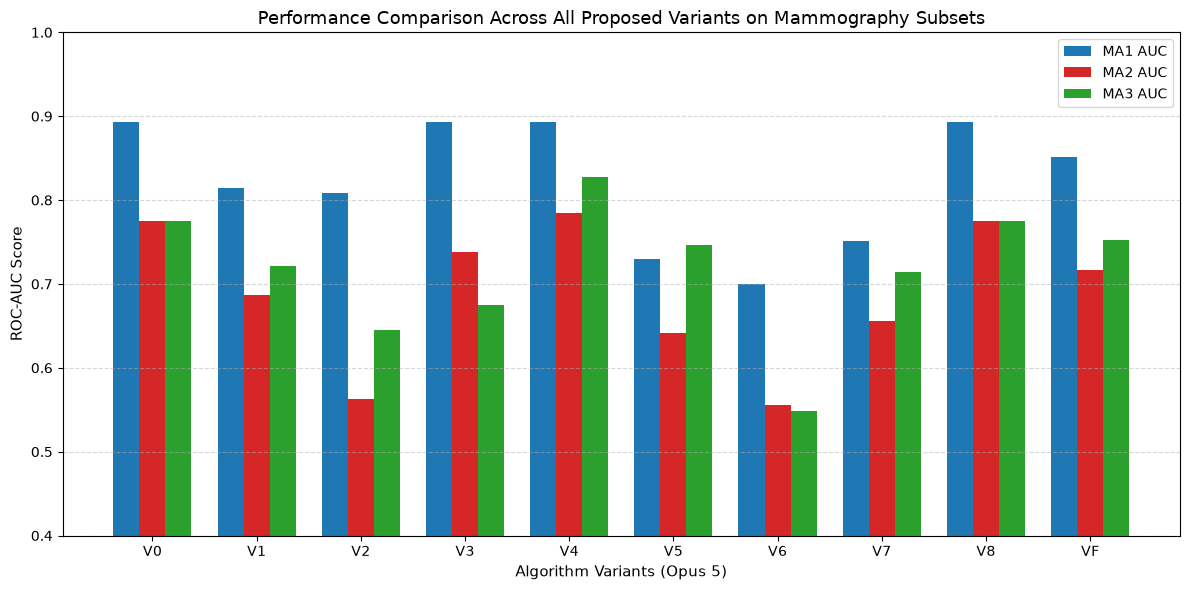

In [38]:
### Cell 12
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
x_pos = np.arange(len(df_comparison))
width = 0.25

plt.bar(x_pos - width, df_comparison["MA1 AUC"], width=width, label='MA1 AUC', color='#1f77b4')
plt.bar(x_pos, df_comparison["MA2 AUC"], width=width, label='MA2 AUC', color='#d62728')
plt.bar(x_pos + width, df_comparison["MA3 AUC"], width=width, label='MA3 AUC', color='#2ca02c')

plt.xlabel('Algorithm Variants (Opus 5)', fontsize=11)
plt.ylabel('ROC-AUC Score', fontsize=11)
plt.title('Performance Comparison Across All Proposed Variants on Mammography Subsets', fontsize=13)
plt.xticks(x_pos, df_comparison["Key"], rotation=0, fontsize=10)
plt.ylim([0.4, 1.0])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

#### ⚪ 1st Implementation >> V4

In [39]:
### Cell 13
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

# Reference baseline (V0) results from paper across lambda in [0.1, 2.0]
# Stored to allow instantaneous baseline comparison without re-running 20 iterations
BASELINE_V0_CURVES = {
    'MA1': [
        {'lambda': 0.1, 'ROC-AUC': 0.3409, 'AP': 0.0168}, {'lambda': 0.2, 'ROC-AUC': 0.4595, 'AP': 0.0509},
        {'lambda': 0.3, 'ROC-AUC': 0.6006, 'AP': 0.0774}, {'lambda': 0.4, 'ROC-AUC': 0.7606, 'AP': 0.1505},
        {'lambda': 0.5, 'ROC-AUC': 0.8931, 'AP': 0.3550}, {'lambda': 0.6, 'ROC-AUC': 0.8874, 'AP': 0.2114},
        {'lambda': 0.7, 'ROC-AUC': 0.8610, 'AP': 0.1315}, {'lambda': 0.8, 'ROC-AUC': 0.8548, 'AP': 0.1018},
        {'lambda': 0.9, 'ROC-AUC': 0.8506, 'AP': 0.0905}, {'lambda': 1.0, 'ROC-AUC': 0.8448, 'AP': 0.0809},
        {'lambda': 1.1, 'ROC-AUC': 0.8277, 'AP': 0.0748}, {'lambda': 1.2, 'ROC-AUC': 0.8196, 'AP': 0.0685},
        {'lambda': 1.3, 'ROC-AUC': 0.8154, 'AP': 0.0640}, {'lambda': 1.4, 'ROC-AUC': 0.8082, 'AP': 0.0601},
        {'lambda': 1.5, 'ROC-AUC': 0.8032, 'AP': 0.0567}, {'lambda': 1.6, 'ROC-AUC': 0.7934, 'AP': 0.0530},
        {'lambda': 1.7, 'ROC-AUC': 0.7858, 'AP': 0.0500}, {'lambda': 1.8, 'ROC-AUC': 0.7787, 'AP': 0.0474},
        {'lambda': 1.9, 'ROC-AUC': 0.7761, 'AP': 0.0457}, {'lambda': 2.0, 'ROC-AUC': 0.7727, 'AP': 0.0442}],
    'MA2': [
        {'lambda': 0.1, 'ROC-AUC': 0.4193, 'AP': 0.0078}, {'lambda': 0.2, 'ROC-AUC': 0.4321, 'AP': 0.0213},
        {'lambda': 0.3, 'ROC-AUC': 0.4875, 'AP': 0.0429}, {'lambda': 0.4, 'ROC-AUC': 0.6339, 'AP': 0.0723},
        {'lambda': 0.5, 'ROC-AUC': 0.7745, 'AP': 0.0626}, {'lambda': 0.6, 'ROC-AUC': 0.7735, 'AP': 0.0373},
        {'lambda': 0.7, 'ROC-AUC': 0.7551, 'AP': 0.0349}, {'lambda': 0.8, 'ROC-AUC': 0.7271, 'AP': 0.0409},
        {'lambda': 0.9, 'ROC-AUC': 0.7110, 'AP': 0.0390}, {'lambda': 1.0, 'ROC-AUC': 0.7135, 'AP': 0.0432},
        {'lambda': 1.1, 'ROC-AUC': 0.7114, 'AP': 0.0442}, {'lambda': 1.2, 'ROC-AUC': 0.7056, 'AP': 0.0461},
        {'lambda': 1.3, 'ROC-AUC': 0.6970, 'AP': 0.0391}, {'lambda': 1.4, 'ROC-AUC': 0.6811, 'AP': 0.0354},
        {'lambda': 1.5, 'ROC-AUC': 0.6759, 'AP': 0.0271}, {'lambda': 1.6, 'ROC-AUC': 0.6704, 'AP': 0.0246},
        {'lambda': 1.7, 'ROC-AUC': 0.6753, 'AP': 0.0213}, {'lambda': 1.8, 'ROC-AUC': 0.6713, 'AP': 0.0193},
        {'lambda': 1.9, 'ROC-AUC': 0.6678, 'AP': 0.0182}, {'lambda': 2.0, 'ROC-AUC': 0.6663, 'AP': 0.0176}],
    'MA3': [
        {'lambda': 0.1, 'ROC-AUC': 0.4075, 'AP': 0.0522}, {'lambda': 0.2, 'ROC-AUC': 0.5280, 'AP': 0.0699},
        {'lambda': 0.3, 'ROC-AUC': 0.6631, 'AP': 0.1572}, {'lambda': 0.4, 'ROC-AUC': 0.7750, 'AP': 0.1195},
        {'lambda': 0.5, 'ROC-AUC': 0.7748, 'AP': 0.0827}, {'lambda': 0.6, 'ROC-AUC': 0.7880, 'AP': 0.1669},
        {'lambda': 0.7, 'ROC-AUC': 0.7610, 'AP': 0.1656}, {'lambda': 0.8, 'ROC-AUC': 0.7126, 'AP': 0.1866},
        {'lambda': 0.9, 'ROC-AUC': 0.7093, 'AP': 0.1638}, {'lambda': 1.0, 'ROC-AUC': 0.7127, 'AP': 0.0999},
        {'lambda': 1.1, 'ROC-AUC': 0.7052, 'AP': 0.0788}, {'lambda': 1.2, 'ROC-AUC': 0.7065, 'AP': 0.0751},
        {'lambda': 1.3, 'ROC-AUC': 0.7036, 'AP': 0.0551}, {'lambda': 1.4, 'ROC-AUC': 0.7200, 'AP': 0.0560},
        {'lambda': 1.5, 'ROC-AUC': 0.7175, 'AP': 0.0456}, {'lambda': 1.6, 'ROC-AUC': 0.7213, 'AP': 0.0443},
        {'lambda': 1.7, 'ROC-AUC': 0.7292, 'AP': 0.0443}, {'lambda': 1.8, 'ROC-AUC': 0.7346, 'AP': 0.0429},
        {'lambda': 1.9, 'ROC-AUC': 0.7351, 'AP': 0.0427}, {'lambda': 2.0, 'ROC-AUC': 0.7351, 'AP': 0.0420}]}

def execute_variant_grid_search(model_cls, data, labels, X_tem, subset_name, variant_name, lambda_range):
    """
    Executes a sequential grid search over lambda_range, prints progress line-by-line,
    displays formatted summary, and renders dual side-by-side plots for ROC-AUC and AP.
    """
    print(f"\n{'='*75}")
    print(f"Executing Grid Search: {variant_name} on {subset_name}")
    print(f"Evaluating {len(lambda_range)} lambda values in [{lambda_range[0]} - {lambda_range[-1]}]")
    print(f"{'='*75}")

    results = []
    for lam in lambda_range:
        model = model_cls(lammda=lam)
        out_scores = model.fit_predict(data, X_index=X_tem)
        auc = roc_auc_score(labels[X_tem], out_scores)
        ap = average_precision_score(labels[X_tem], out_scores)
        results.append({'lambda': round(lam, 2), 'ROC-AUC': auc, 'AP': ap})
        print(f"lambda = {lam:4.1f} | ROC-AUC = {auc:.4f} | AP = {ap:.4f}")

    # Identify optimal performance points
    best_auc = max(results, key=lambda x: x['ROC-AUC'])
    best_ap = max(results, key=lambda x: x['AP'])
    
    print(f"\nOptimal Results for {variant_name} on {subset_name}:")
    print(f"  Best ROC-AUC: {best_auc['ROC-AUC']:.4f} (at lambda = {best_auc['lambda']})")
    print(f"  Best AP:      {best_ap['AP']:.4f} (at lambda = {best_ap['lambda']})")

    # Dual-metric visualization
    v0_data = BASELINE_V0_CURVES[subset_name]
    lams = [r['lambda'] for r in results]
    var_auc = [r['ROC-AUC'] for r in results]
    var_ap = [r['AP'] for r in results]
    v0_auc = [r['ROC-AUC'] for r in v0_data]
    v0_ap = [r['AP'] for r in v0_data]
    best_v0_auc = max(v0_data, key=lambda x: x['ROC-AUC'])
    best_v0_ap = max(v0_data, key=lambda x: x['AP'])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Subplot 1: ROC-AUC vs Lambda
    ax1.plot(lams, v0_auc, marker='o', linestyle='--', color='#7f7f7f', label=f"V0 Baseline (Peak: {best_v0_auc['ROC-AUC']:.4f} @ λ={best_v0_auc['lambda']})")
    ax1.plot(lams, var_auc, marker='s', linestyle='-', color='#d62728', linewidth=2, label=f"{variant_name} (Peak: {best_auc['ROC-AUC']:.4f} @ λ={best_auc['lambda']})")
    ax1.scatter([best_auc['lambda']], [best_auc['ROC-AUC']], color='black', s=100, zorder=5)
    ax1.set_title(f"{subset_name}: ROC-AUC vs $\lambda$", fontsize=12)
    ax1.set_xlabel('$\lambda$', fontsize=11)
    ax1.set_ylabel('ROC-AUC', fontsize=11)
    ax1.set_xticks(lams)
    ax1.tick_params(axis='x', rotation=45)
    ax1.grid(alpha=0.3)
    ax1.legend()

    # Subplot 2: AP vs Lambda
    ax2.plot(lams, v0_ap, marker='o', linestyle='--', color='#7f7f7f', label=f"V0 Baseline (Peak: {best_v0_ap['AP']:.4f} @ λ={best_v0_ap['lambda']})")
    ax2.plot(lams, var_ap, marker='^', linestyle='-', color='#1f77b4', linewidth=2, label=f"{variant_name} (Peak: {best_ap['AP']:.4f} @ λ={best_ap['lambda']})")
    ax2.scatter([best_ap['lambda']], [best_ap['AP']], color='black', s=100, zorder=5)
    ax2.set_title(f"{subset_name}: Average Precision (AP) vs $\lambda$", fontsize=12)
    ax2.set_xlabel('$\lambda$', fontsize=11)
    ax2.set_ylabel('AP', fontsize=11)
    ax2.set_xticks(lams)
    ax2.tick_params(axis='x', rotation=45)
    ax2.grid(alpha=0.3)
    ax2.legend()

    plt.tight_layout()
    plt.show()

    return results

<>:87: SyntaxWarning: invalid escape sequence '\l'
<>:88: SyntaxWarning: invalid escape sequence '\l'
<>:99: SyntaxWarning: invalid escape sequence '\l'
<>:100: SyntaxWarning: invalid escape sequence '\l'
<>:87: SyntaxWarning: invalid escape sequence '\l'
<>:88: SyntaxWarning: invalid escape sequence '\l'
<>:99: SyntaxWarning: invalid escape sequence '\l'
<>:100: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_253963/2679403080.py:87: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title(f"{subset_name}: ROC-AUC vs $\lambda$", fontsize=12)
/tmp/ipykernel_253963/2679403080.py:88: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_xlabel('$\lambda$', fontsize=11)
/tmp/ipykernel_253963/2679403080.py:99: SyntaxWarning: invalid escape sequence '\l'
  ax2.set_title(f"{subset_name}: Average Precision (AP) vs $\lambda$", fontsize=12)
/tmp/ipykernel_253963/2679403080.py:100: SyntaxWarning: invalid escape sequence '\l'
  ax2.set_xlabel('$\lambda$', fontsize=11)



Executing Grid Search: Variant 4 (Tiered NDF) on MA1
Evaluating 20 lambda values in [0.1 - 2.0]
lambda =  0.1 | ROC-AUC = 0.3409 | AP = 0.0168
lambda =  0.2 | ROC-AUC = 0.4595 | AP = 0.0509
lambda =  0.3 | ROC-AUC = 0.6019 | AP = 0.0874
lambda =  0.4 | ROC-AUC = 0.7607 | AP = 0.1504
lambda =  0.5 | ROC-AUC = 0.8928 | AP = 0.3556
lambda =  0.6 | ROC-AUC = 0.8872 | AP = 0.2147
lambda =  0.7 | ROC-AUC = 0.8545 | AP = 0.1391
lambda =  0.8 | ROC-AUC = 0.8495 | AP = 0.1105
lambda =  0.9 | ROC-AUC = 0.8487 | AP = 0.1063
lambda =  1.0 | ROC-AUC = 0.8477 | AP = 0.0964
lambda =  1.1 | ROC-AUC = 0.8437 | AP = 0.0956
lambda =  1.2 | ROC-AUC = 0.8430 | AP = 0.0908
lambda =  1.3 | ROC-AUC = 0.8405 | AP = 0.0871
lambda =  1.4 | ROC-AUC = 0.8403 | AP = 0.0859
lambda =  1.5 | ROC-AUC = 0.8357 | AP = 0.0821
lambda =  1.6 | ROC-AUC = 0.8298 | AP = 0.0781
lambda =  1.7 | ROC-AUC = 0.8263 | AP = 0.0746
lambda =  1.8 | ROC-AUC = 0.8207 | AP = 0.0702
lambda =  1.9 | ROC-AUC = 0.8179 | AP = 0.0672
lambda =  

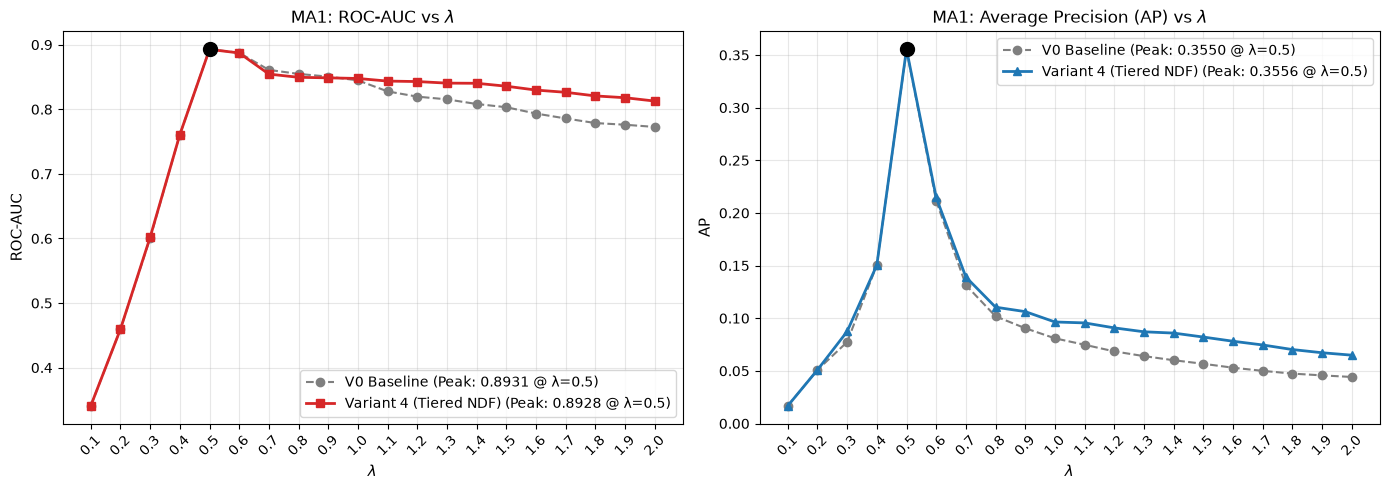

In [40]:
### Cell 14
# Standard lambda search space from 0.1 to 2.0 with step 0.1
lambda_grid = [round(x, 1) for x in np.arange(0.1, 2.1, 0.1)]

# Execute Variant 4 on MA1
v4_ma1_results = execute_variant_grid_search(
    model_cls=Variant4TieredEvidence,
    data=X,
    labels=y,
    X_tem=X_tem_ma1,
    subset_name="MA1",
    variant_name="Variant 4 (Tiered NDF)",
    lambda_range=lambda_grid)


Executing Grid Search: Variant 4 (Tiered NDF) on MA2
Evaluating 20 lambda values in [0.1 - 2.0]
lambda =  0.1 | ROC-AUC = 0.4193 | AP = 0.0078
lambda =  0.2 | ROC-AUC = 0.4322 | AP = 0.0287
lambda =  0.3 | ROC-AUC = 0.4876 | AP = 0.0482
lambda =  0.4 | ROC-AUC = 0.6362 | AP = 0.0669
lambda =  0.5 | ROC-AUC = 0.7842 | AP = 0.0698
lambda =  0.6 | ROC-AUC = 0.7888 | AP = 0.0539
lambda =  0.7 | ROC-AUC = 0.7759 | AP = 0.0496
lambda =  0.8 | ROC-AUC = 0.7089 | AP = 0.0224
lambda =  0.9 | ROC-AUC = 0.7006 | AP = 0.0169
lambda =  1.0 | ROC-AUC = 0.7010 | AP = 0.0189
lambda =  1.1 | ROC-AUC = 0.6890 | AP = 0.0173
lambda =  1.2 | ROC-AUC = 0.6894 | AP = 0.0185
lambda =  1.3 | ROC-AUC = 0.6719 | AP = 0.0157
lambda =  1.4 | ROC-AUC = 0.6616 | AP = 0.0136
lambda =  1.5 | ROC-AUC = 0.6653 | AP = 0.0137
lambda =  1.6 | ROC-AUC = 0.6608 | AP = 0.0132
lambda =  1.7 | ROC-AUC = 0.6611 | AP = 0.0128
lambda =  1.8 | ROC-AUC = 0.6588 | AP = 0.0126
lambda =  1.9 | ROC-AUC = 0.6576 | AP = 0.0126
lambda =  

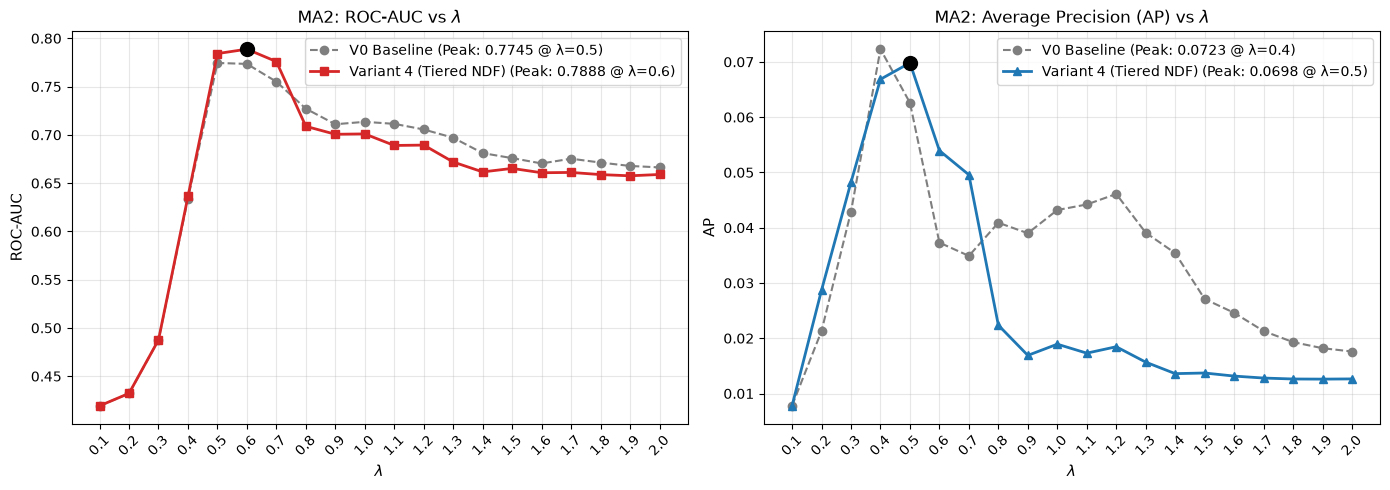

In [41]:
### Cell 15
# Execute Variant 4 on MA2
v4_ma2_results = execute_variant_grid_search(
    model_cls=Variant4TieredEvidence,
    data=X,
    labels=y,
    X_tem=X_tem_ma2,
    subset_name="MA2",
    variant_name="Variant 4 (Tiered NDF)",
    lambda_range=lambda_grid)


Executing Grid Search: Variant 4 (Tiered NDF) on MA3
Evaluating 20 lambda values in [0.1 - 2.0]
lambda =  0.1 | ROC-AUC = 0.4077 | AP = 0.0522
lambda =  0.2 | ROC-AUC = 0.5287 | AP = 0.1049
lambda =  0.3 | ROC-AUC = 0.6640 | AP = 0.1715
lambda =  0.4 | ROC-AUC = 0.7998 | AP = 0.1327
lambda =  0.5 | ROC-AUC = 0.8274 | AP = 0.1440
lambda =  0.6 | ROC-AUC = 0.7872 | AP = 0.1101
lambda =  0.7 | ROC-AUC = 0.7568 | AP = 0.0568
lambda =  0.8 | ROC-AUC = 0.7049 | AP = 0.0365
lambda =  0.9 | ROC-AUC = 0.6875 | AP = 0.0263
lambda =  1.0 | ROC-AUC = 0.6687 | AP = 0.0212
lambda =  1.1 | ROC-AUC = 0.6683 | AP = 0.0177
lambda =  1.2 | ROC-AUC = 0.6716 | AP = 0.0153
lambda =  1.3 | ROC-AUC = 0.6655 | AP = 0.0139
lambda =  1.4 | ROC-AUC = 0.6751 | AP = 0.0133
lambda =  1.5 | ROC-AUC = 0.6739 | AP = 0.0131
lambda =  1.6 | ROC-AUC = 0.6712 | AP = 0.0129
lambda =  1.7 | ROC-AUC = 0.6766 | AP = 0.0129
lambda =  1.8 | ROC-AUC = 0.6811 | AP = 0.0127
lambda =  1.9 | ROC-AUC = 0.6963 | AP = 0.0129
lambda =  

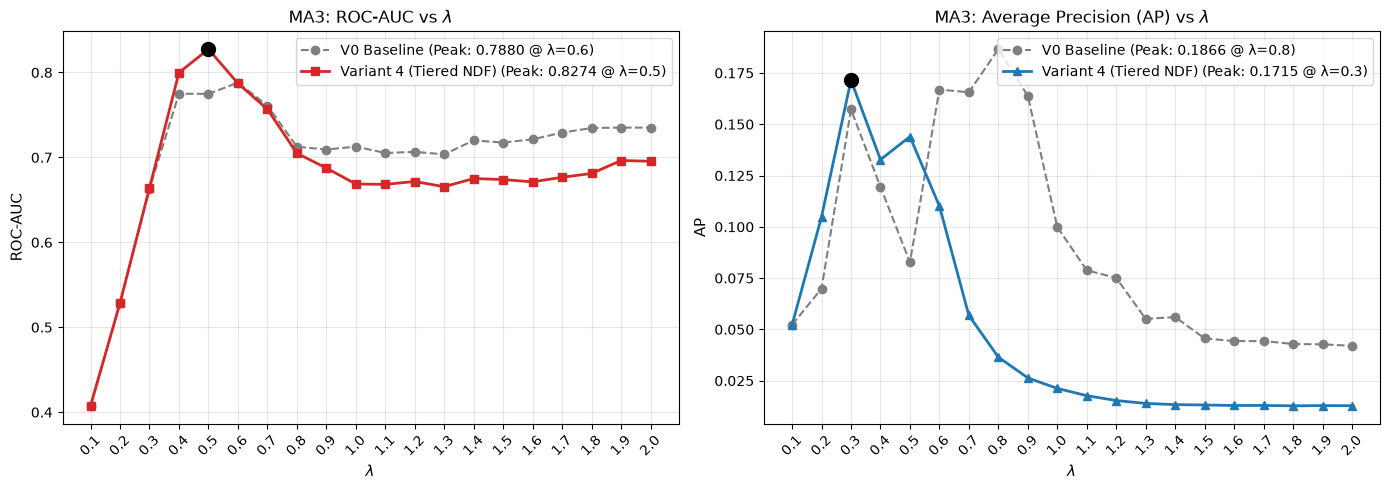

In [42]:
### Cell 16
# Execute Variant 4 on MA3
v4_ma3_results = execute_variant_grid_search(
    model_cls=Variant4TieredEvidence,
    data=X,
    labels=y,
    X_tem=X_tem_ma3,
    subset_name="MA3",
    variant_name="Variant 4 (Tiered NDF)",
    lambda_range=lambda_grid)

In [43]:
### Cell 17
# Tabular synthesis comparing optimal grid-search outcomes for Variant 4 vs Baseline V0
v4_summary_table = []

for name, results in [('MA1', v4_ma1_results), ('MA2', v4_ma2_results), ('MA3', v4_ma3_results)]:
    v0_data = BASELINE_V0_CURVES[name]
    best_v0_auc = max(v0_data, key=lambda x: x['ROC-AUC'])
    best_v0_ap = max(v0_data, key=lambda x: x['AP'])
    
    best_v4_auc = max(results, key=lambda x: x['ROC-AUC'])
    best_v4_ap = max(results, key=lambda x: x['AP'])
    
    v4_summary_table.append({
        "Dataset": name,
        "V0 Best AUC": f"{best_v0_auc['ROC-AUC']:.4f} (@ λ={best_v0_auc['lambda']})",
        "V4 Best AUC": f"{best_v4_auc['ROC-AUC']:.4f} (@ λ={best_v4_auc['lambda']})",
        "AUC Gain": f"{(best_v4_auc['ROC-AUC'] - best_v0_auc['ROC-AUC']):+.4f}",
        "V0 Best AP": f"{best_v0_ap['AP']:.4f} (@ λ={best_v0_ap['lambda']})",
        "V4 Best AP": f"{best_v4_ap['AP']:.4f} (@ λ={best_v4_ap['lambda']})",
        "AP Gain": f"{(best_v4_ap['AP'] - best_v0_ap['AP']):+.4f}"})

print("\n--- Summary Benchmark: Variant 4 (Tiered NDF) vs Baseline V0 ---")
display(pd.DataFrame(v4_summary_table))


--- Summary Benchmark: Variant 4 (Tiered NDF) vs Baseline V0 ---


,Dataset,V0 Best AUC,V4 Best AUC,AUC Gain,V0 Best AP,V4 Best AP,AP Gain
0,MA1,0.8931 (@ λ=0.5),0.8928 (@ λ=0.5),-0.0003,0.3550 (@ λ=0.5),0.3556 (@ λ=0.5),+0.0006
1,MA2,0.7745 (@ λ=0.5),0.7888 (@ λ=0.6),+0.0143,0.0723 (@ λ=0.4),0.0698 (@ λ=0.5),-0.0025
2,MA3,0.7880 (@ λ=0.6),0.8274 (@ λ=0.5),+0.0394,0.1866 (@ λ=0.8),0.1715 (@ λ=0.3),-0.0151


#### ⚪ 2nd Implementation >> V3


Executing Grid Search: Variant 3 (Subspace Augmentation) on MA1
Evaluating 20 lambda values in [0.1 - 2.0]
lambda =  0.1 | ROC-AUC = 0.3145 | AP = 0.0155
lambda =  0.2 | ROC-AUC = 0.4576 | AP = 0.0493
lambda =  0.3 | ROC-AUC = 0.5999 | AP = 0.0767
lambda =  0.4 | ROC-AUC = 0.7598 | AP = 0.1393
lambda =  0.5 | ROC-AUC = 0.8927 | AP = 0.3718
lambda =  0.6 | ROC-AUC = 0.8851 | AP = 0.2255
lambda =  0.7 | ROC-AUC = 0.8472 | AP = 0.1818
lambda =  0.8 | ROC-AUC = 0.8418 | AP = 0.1665
lambda =  0.9 | ROC-AUC = 0.8381 | AP = 0.1566
lambda =  1.0 | ROC-AUC = 0.8307 | AP = 0.1448
lambda =  1.1 | ROC-AUC = 0.8227 | AP = 0.1423
lambda =  1.2 | ROC-AUC = 0.8092 | AP = 0.1353
lambda =  1.3 | ROC-AUC = 0.7795 | AP = 0.1309
lambda =  1.4 | ROC-AUC = 0.7728 | AP = 0.1309
lambda =  1.5 | ROC-AUC = 0.7745 | AP = 0.1247
lambda =  1.6 | ROC-AUC = 0.7682 | AP = 0.1190
lambda =  1.7 | ROC-AUC = 0.7626 | AP = 0.1129
lambda =  1.8 | ROC-AUC = 0.7564 | AP = 0.1124
lambda =  1.9 | ROC-AUC = 0.7552 | AP = 0.1116

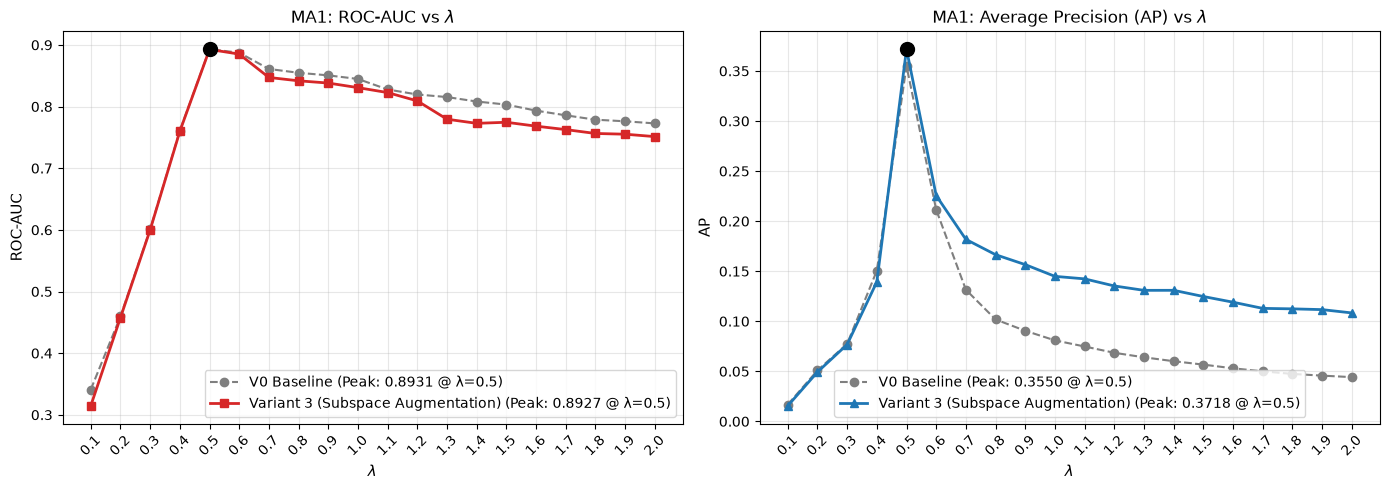

In [44]:
### Cell 18
# Execute Variant 3 on MA1
v3_ma1_results = execute_variant_grid_search(
    model_cls=Variant3SubspaceAugmented,
    data=X,
    labels=y,
    X_tem=X_tem_ma1,
    subset_name="MA1",
    variant_name="Variant 3 (Subspace Augmentation)",
    lambda_range=lambda_grid)


Executing Grid Search: Variant 3 (Subspace Augmentation) on MA2
Evaluating 20 lambda values in [0.1 - 2.0]
lambda =  0.1 | ROC-AUC = 0.3915 | AP = 0.0074
lambda =  0.2 | ROC-AUC = 0.4292 | AP = 0.0099
lambda =  0.3 | ROC-AUC = 0.4802 | AP = 0.0134
lambda =  0.4 | ROC-AUC = 0.6122 | AP = 0.0207
lambda =  0.5 | ROC-AUC = 0.7382 | AP = 0.0363
lambda =  0.6 | ROC-AUC = 0.7324 | AP = 0.0179
lambda =  0.7 | ROC-AUC = 0.7190 | AP = 0.0182
lambda =  0.8 | ROC-AUC = 0.6726 | AP = 0.0595
lambda =  0.9 | ROC-AUC = 0.6714 | AP = 0.0649
lambda =  1.0 | ROC-AUC = 0.6821 | AP = 0.0837
lambda =  1.1 | ROC-AUC = 0.6738 | AP = 0.0912
lambda =  1.2 | ROC-AUC = 0.6765 | AP = 0.0937
lambda =  1.3 | ROC-AUC = 0.6687 | AP = 0.0988
lambda =  1.4 | ROC-AUC = 0.6441 | AP = 0.0980
lambda =  1.5 | ROC-AUC = 0.5711 | AP = 0.0941
lambda =  1.6 | ROC-AUC = 0.5719 | AP = 0.0935
lambda =  1.7 | ROC-AUC = 0.5791 | AP = 0.0957
lambda =  1.8 | ROC-AUC = 0.5749 | AP = 0.0958
lambda =  1.9 | ROC-AUC = 0.5701 | AP = 0.0858

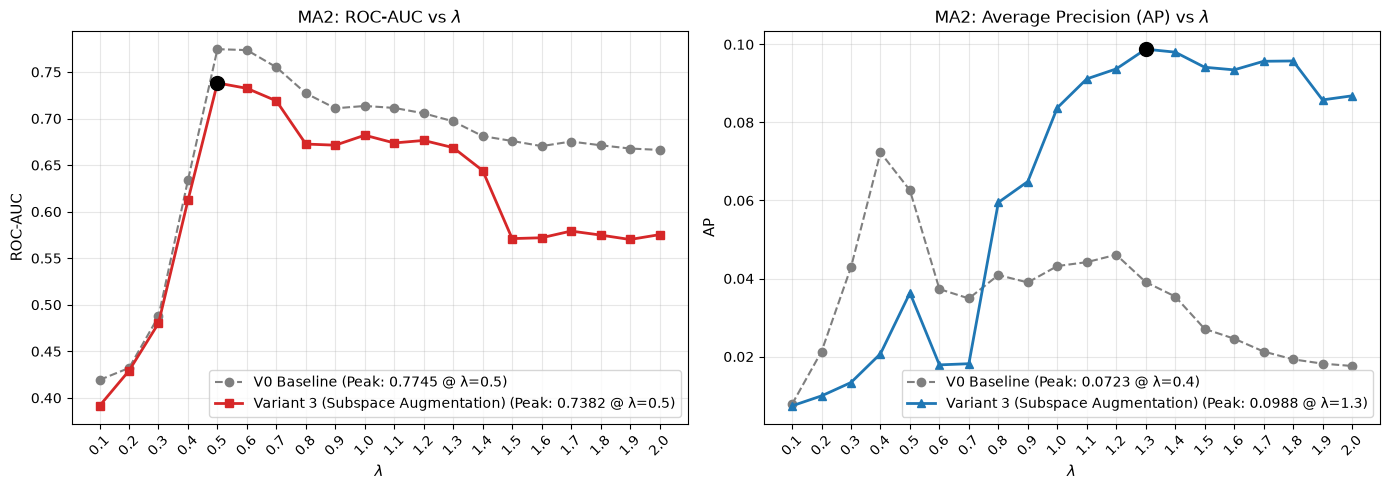

In [45]:
### Cell 19
# Execute Variant 3 on MA2
v3_ma2_results = execute_variant_grid_search(
    model_cls=Variant3SubspaceAugmented,
    data=X,
    labels=y,
    X_tem=X_tem_ma2,
    subset_name="MA2",
    variant_name="Variant 3 (Subspace Augmentation)",
    lambda_range=lambda_grid)


Executing Grid Search: Variant 3 (Subspace Augmentation) on MA3
Evaluating 20 lambda values in [0.1 - 2.0]
lambda =  0.1 | ROC-AUC = 0.3787 | AP = 0.0352
lambda =  0.2 | ROC-AUC = 0.5255 | AP = 0.0592
lambda =  0.3 | ROC-AUC = 0.6403 | AP = 0.0429
lambda =  0.4 | ROC-AUC = 0.7304 | AP = 0.0567
lambda =  0.5 | ROC-AUC = 0.6744 | AP = 0.0180
lambda =  0.6 | ROC-AUC = 0.7782 | AP = 0.2410
lambda =  0.7 | ROC-AUC = 0.7629 | AP = 0.2668
lambda =  0.8 | ROC-AUC = 0.7090 | AP = 0.2848
lambda =  0.9 | ROC-AUC = 0.6953 | AP = 0.2888
lambda =  1.0 | ROC-AUC = 0.6749 | AP = 0.2923
lambda =  1.1 | ROC-AUC = 0.6715 | AP = 0.2943
lambda =  1.2 | ROC-AUC = 0.6747 | AP = 0.3040
lambda =  1.3 | ROC-AUC = 0.7043 | AP = 0.3092
lambda =  1.4 | ROC-AUC = 0.7216 | AP = 0.3045
lambda =  1.5 | ROC-AUC = 0.7226 | AP = 0.3060
lambda =  1.6 | ROC-AUC = 0.7221 | AP = 0.3025
lambda =  1.7 | ROC-AUC = 0.7474 | AP = 0.2904
lambda =  1.8 | ROC-AUC = 0.7465 | AP = 0.2874
lambda =  1.9 | ROC-AUC = 0.7505 | AP = 0.2895

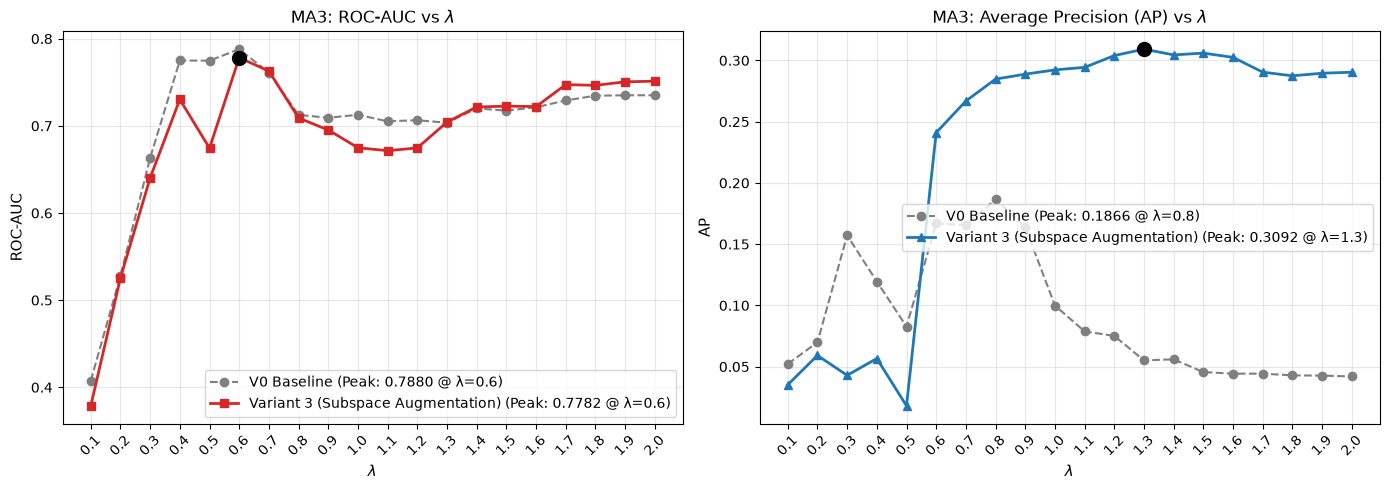

In [46]:
### Cell 20
# Execute Variant 3 on MA3
v3_ma3_results = execute_variant_grid_search(
    model_cls=Variant3SubspaceAugmented,
    data=X,
    labels=y,
    X_tem=X_tem_ma3,
    subset_name="MA3",
    variant_name="Variant 3 (Subspace Augmentation)",
    lambda_range=lambda_grid)

In [47]:
### Cell 21
# Tabular synthesis comparing optimal grid-search outcomes for Variant 3 vs Baseline V0
v3_summary_table = []

for name, results in [('MA1', v3_ma1_results), ('MA2', v3_ma2_results), ('MA3', v3_ma3_results)]:
    v0_data = BASELINE_V0_CURVES[name]
    best_v0_auc = max(v0_data, key=lambda x: x['ROC-AUC'])
    best_v0_ap = max(v0_data, key=lambda x: x['AP'])
    
    best_v3_auc = max(results, key=lambda x: x['ROC-AUC'])
    best_v3_ap = max(results, key=lambda x: x['AP'])
    
    v3_summary_table.append({
        "Dataset": name,
        "V0 Best AUC": f"{best_v0_auc['ROC-AUC']:.4f} (@ λ={best_v0_auc['lambda']})",
        "V3 Best AUC": f"{best_v3_auc['ROC-AUC']:.4f} (@ λ={best_v3_auc['lambda']})",
        "AUC Gain": f"{(best_v3_auc['ROC-AUC'] - best_v0_auc['ROC-AUC']):+.4f}",
        "V0 Best AP": f"{best_v0_ap['AP']:.4f} (@ λ={best_v0_ap['lambda']})",
        "V3 Best AP": f"{best_v3_ap['AP']:.4f} (@ λ={best_v3_ap['lambda']})",
        "AP Gain": f"{(best_v3_ap['AP'] - best_v0_ap['AP']):+.4f}"})

print("\n--- Summary Benchmark: Variant 3 (Subspace Augmentation) vs Baseline V0 ---")
display(pd.DataFrame(v3_summary_table))


--- Summary Benchmark: Variant 3 (Subspace Augmentation) vs Baseline V0 ---


,Dataset,V0 Best AUC,V3 Best AUC,AUC Gain,V0 Best AP,V3 Best AP,AP Gain
0,MA1,0.8931 (@ λ=0.5),0.8927 (@ λ=0.5),-0.0004,0.3550 (@ λ=0.5),0.3718 (@ λ=0.5),+0.0168
1,MA2,0.7745 (@ λ=0.5),0.7382 (@ λ=0.5),-0.0363,0.0723 (@ λ=0.4),0.0988 (@ λ=1.3),+0.0265
2,MA3,0.7880 (@ λ=0.6),0.7782 (@ λ=0.6),-0.0098,0.1866 (@ λ=0.8),0.3092 (@ λ=1.3),+0.1226


#### ⚪ 3rd Implementation >> V2


Executing Grid Search: Variant 2 (Discriminative Weights) on MA1
Evaluating 20 lambda values in [0.1 - 2.0]
lambda =  0.1 | ROC-AUC = 0.3391 | AP = 0.0162
lambda =  0.2 | ROC-AUC = 0.4169 | AP = 0.0405
lambda =  0.3 | ROC-AUC = 0.6340 | AP = 0.0758
lambda =  0.4 | ROC-AUC = 0.5154 | AP = 0.1224
lambda =  0.5 | ROC-AUC = 0.8086 | AP = 0.2979
lambda =  0.6 | ROC-AUC = 0.8675 | AP = 0.1643
lambda =  0.7 | ROC-AUC = 0.8527 | AP = 0.1228
lambda =  0.8 | ROC-AUC = 0.8255 | AP = 0.1116
lambda =  0.9 | ROC-AUC = 0.8304 | AP = 0.1445
lambda =  1.0 | ROC-AUC = 0.8718 | AP = 0.1545
lambda =  1.1 | ROC-AUC = 0.8770 | AP = 0.1339
lambda =  1.2 | ROC-AUC = 0.8597 | AP = 0.1134
lambda =  1.3 | ROC-AUC = 0.8158 | AP = 0.0900
lambda =  1.4 | ROC-AUC = 0.7826 | AP = 0.0779
lambda =  1.5 | ROC-AUC = 0.7699 | AP = 0.0704
lambda =  1.6 | ROC-AUC = 0.7617 | AP = 0.0649
lambda =  1.7 | ROC-AUC = 0.7534 | AP = 0.0596
lambda =  1.8 | ROC-AUC = 0.7506 | AP = 0.0568
lambda =  1.9 | ROC-AUC = 0.7502 | AP = 0.054

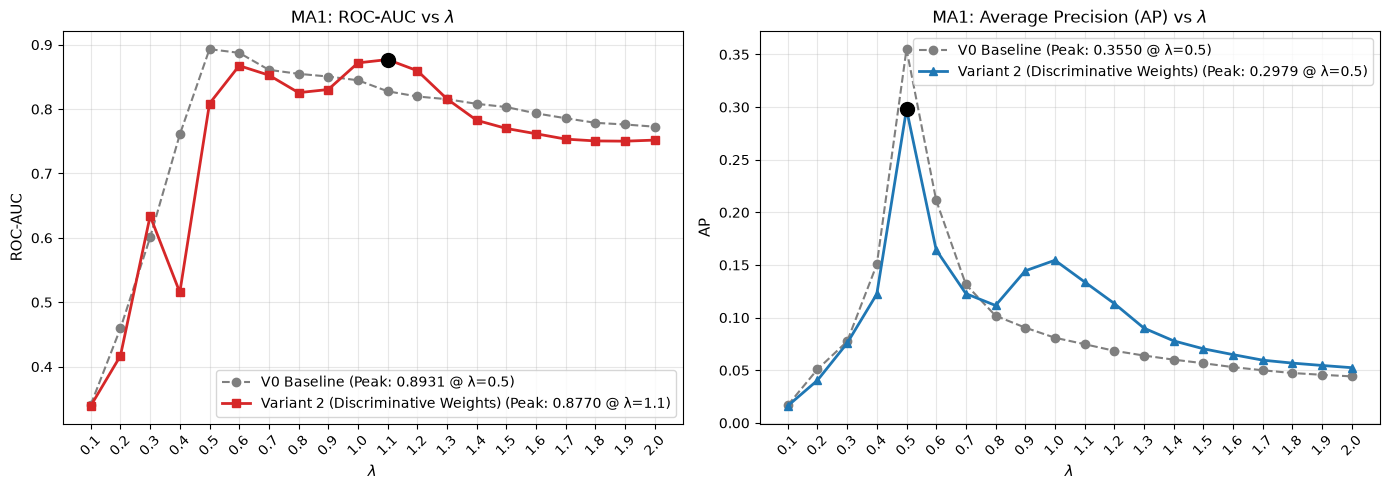

In [48]:
### Cell 22
# Execute Variant 2 on MA1
v2_ma1_results = execute_variant_grid_search(
    model_cls=Variant2DiscriminativeWeights,
    data=X,
    labels=y,
    X_tem=X_tem_ma1,
    subset_name="MA1",
    variant_name="Variant 2 (Discriminative Weights)",
    lambda_range=lambda_grid)


Executing Grid Search: Variant 2 (Discriminative Weights) on MA2
Evaluating 20 lambda values in [0.1 - 2.0]
lambda =  0.1 | ROC-AUC = 0.4291 | AP = 0.0067
lambda =  0.2 | ROC-AUC = 0.4411 | AP = 0.0073
lambda =  0.3 | ROC-AUC = 0.5105 | AP = 0.0093
lambda =  0.4 | ROC-AUC = 0.5656 | AP = 0.0110
lambda =  0.5 | ROC-AUC = 0.5626 | AP = 0.0101
lambda =  0.6 | ROC-AUC = 0.5058 | AP = 0.0076
lambda =  0.7 | ROC-AUC = 0.5218 | AP = 0.0078
lambda =  0.8 | ROC-AUC = 0.6704 | AP = 0.0172
lambda =  0.9 | ROC-AUC = 0.6688 | AP = 0.0143
lambda =  1.0 | ROC-AUC = 0.6965 | AP = 0.0170
lambda =  1.1 | ROC-AUC = 0.6964 | AP = 0.0149
lambda =  1.2 | ROC-AUC = 0.6892 | AP = 0.0143
lambda =  1.3 | ROC-AUC = 0.6783 | AP = 0.0127
lambda =  1.4 | ROC-AUC = 0.6675 | AP = 0.0117
lambda =  1.5 | ROC-AUC = 0.5878 | AP = 0.0126
lambda =  1.6 | ROC-AUC = 0.5908 | AP = 0.0121
lambda =  1.7 | ROC-AUC = 0.6193 | AP = 0.0123
lambda =  1.8 | ROC-AUC = 0.6364 | AP = 0.0125
lambda =  1.9 | ROC-AUC = 0.6396 | AP = 0.012

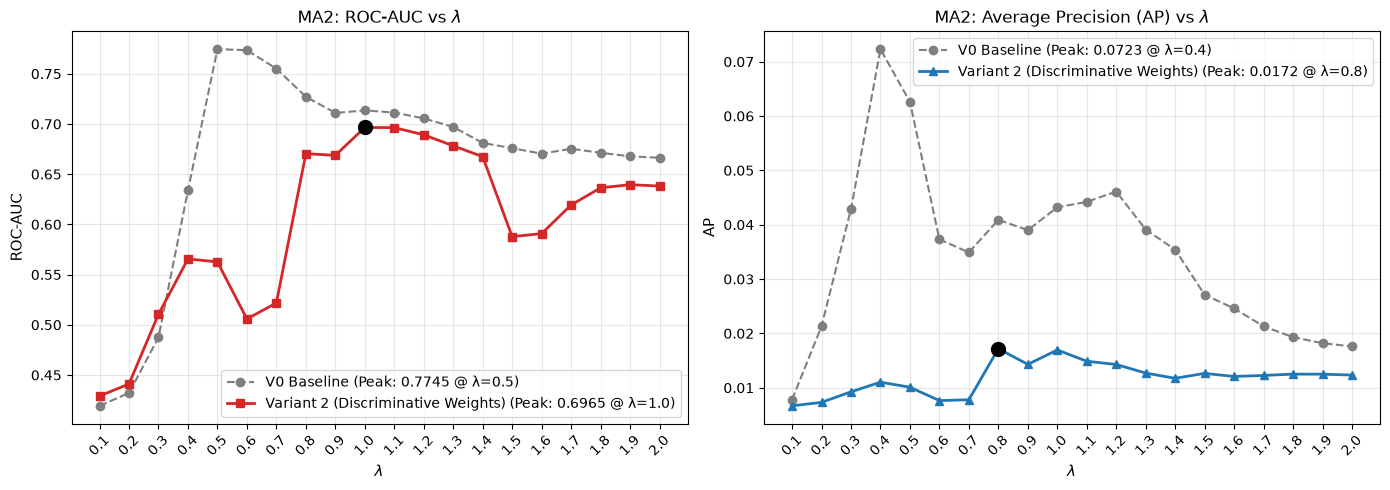

In [49]:
### Cell 23
# Execute Variant 2 on MA2
v2_ma2_results = execute_variant_grid_search(
    model_cls=Variant2DiscriminativeWeights,
    data=X,
    labels=y,
    X_tem=X_tem_ma2,
    subset_name="MA2",
    variant_name="Variant 2 (Discriminative Weights)",
    lambda_range=lambda_grid)


Executing Grid Search: Variant 2 (Discriminative Weights) on MA3
Evaluating 20 lambda values in [0.1 - 2.0]
lambda =  0.1 | ROC-AUC = 0.3179 | AP = 0.0050
lambda =  0.2 | ROC-AUC = 0.4621 | AP = 0.0201
lambda =  0.3 | ROC-AUC = 0.5755 | AP = 0.0232
lambda =  0.4 | ROC-AUC = 0.6762 | AP = 0.0315
lambda =  0.5 | ROC-AUC = 0.6450 | AP = 0.0155
lambda =  0.6 | ROC-AUC = 0.5195 | AP = 0.0168
lambda =  0.7 | ROC-AUC = 0.5716 | AP = 0.0098
lambda =  0.8 | ROC-AUC = 0.5773 | AP = 0.0081
lambda =  0.9 | ROC-AUC = 0.5426 | AP = 0.0072
lambda =  1.0 | ROC-AUC = 0.5360 | AP = 0.0070
lambda =  1.1 | ROC-AUC = 0.5429 | AP = 0.0071
lambda =  1.2 | ROC-AUC = 0.5408 | AP = 0.0072
lambda =  1.3 | ROC-AUC = 0.5397 | AP = 0.0072
lambda =  1.4 | ROC-AUC = 0.5536 | AP = 0.0074
lambda =  1.5 | ROC-AUC = 0.5637 | AP = 0.0075
lambda =  1.6 | ROC-AUC = 0.5900 | AP = 0.0079
lambda =  1.7 | ROC-AUC = 0.5931 | AP = 0.0079
lambda =  1.8 | ROC-AUC = 0.5976 | AP = 0.0080
lambda =  1.9 | ROC-AUC = 0.6061 | AP = 0.008

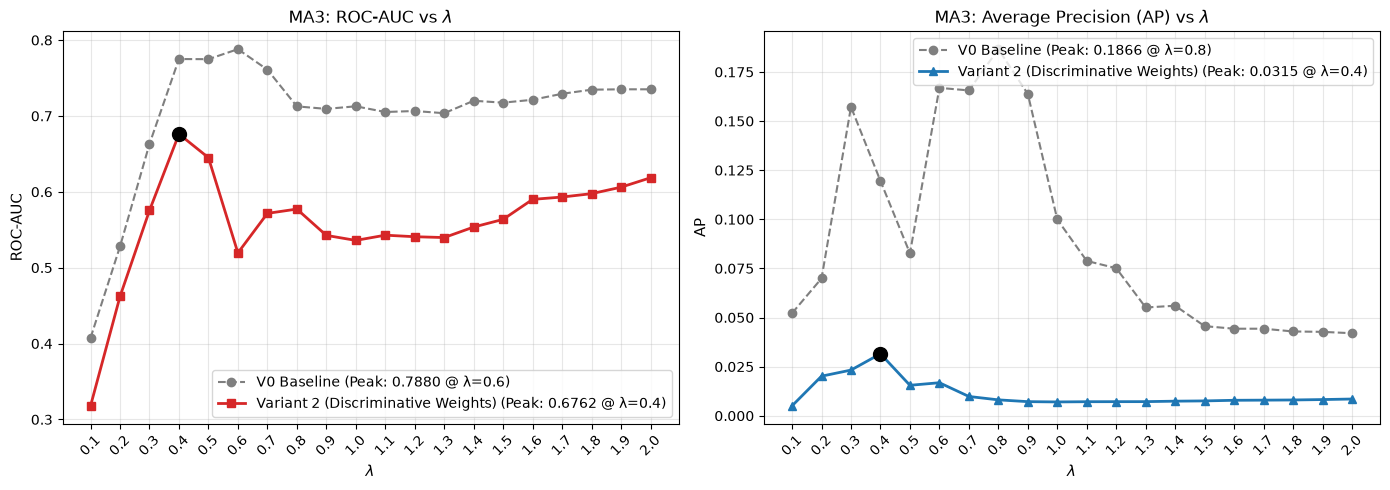

In [50]:
### Cell 24
# Execute Variant 2 on MA3
v2_ma3_results = execute_variant_grid_search(
    model_cls=Variant2DiscriminativeWeights,
    data=X,
    labels=y,
    X_tem=X_tem_ma3,
    subset_name="MA3",
    variant_name="Variant 2 (Discriminative Weights)",
    lambda_range=lambda_grid)

In [51]:
### Cell 25
# Tabular synthesis comparing optimal grid-search outcomes for Variant 2 vs Baseline V0
v2_summary_table = []

for name, results in [('MA1', v2_ma1_results), ('MA2', v2_ma2_results), ('MA3', v2_ma3_results)]:
    v0_data = BASELINE_V0_CURVES[name]
    best_v0_auc = max(v0_data, key=lambda x: x['ROC-AUC'])
    best_v0_ap = max(v0_data, key=lambda x: x['AP'])
    
    best_v2_auc = max(results, key=lambda x: x['ROC-AUC'])
    best_v2_ap = max(results, key=lambda x: x['AP'])
    
    v2_summary_table.append({
        "Dataset": name,
        "V0 Best AUC": f"{best_v0_auc['ROC-AUC']:.4f} (@ λ={best_v0_auc['lambda']})",
        "V2 Best AUC": f"{best_v2_auc['ROC-AUC']:.4f} (@ λ={best_v2_auc['lambda']})",
        "AUC Gain": f"{(best_v2_auc['ROC-AUC'] - best_v0_auc['ROC-AUC']):+.4f}",
        "V0 Best AP": f"{best_v0_ap['AP']:.4f} (@ λ={best_v0_ap['lambda']})",
        "V2 Best AP": f"{best_v2_ap['AP']:.4f} (@ λ={best_v2_ap['lambda']})",
        "AP Gain": f"{(best_v2_ap['AP'] - best_v0_ap['AP']):+.4f}"})

print("\n--- Summary Benchmark: Variant 2 (Discriminative Weights) vs Baseline V0 ---")
display(pd.DataFrame(v2_summary_table))


--- Summary Benchmark: Variant 2 (Discriminative Weights) vs Baseline V0 ---


,Dataset,V0 Best AUC,V2 Best AUC,AUC Gain,V0 Best AP,V2 Best AP,AP Gain
0,MA1,0.8931 (@ λ=0.5),0.8770 (@ λ=1.1),-0.0161,0.3550 (@ λ=0.5),0.2979 (@ λ=0.5),-0.0571
1,MA2,0.7745 (@ λ=0.5),0.6965 (@ λ=1.0),-0.0780,0.0723 (@ λ=0.4),0.0172 (@ λ=0.8),-0.0551
2,MA3,0.7880 (@ λ=0.6),0.6762 (@ λ=0.4),-0.1118,0.1866 (@ λ=0.8),0.0315 (@ λ=0.4),-0.1551


#### ⚪ 4th Implementation >> V3 + V4

In [ ]:
### Cell 26
# Ensure ThreeWNCROD base engine is imported from the loaded Opus module
if 'ThreeWNCROD' not in globals():
    if 'opus_module' in globals():
        ThreeWNCROD = getattr(opus_module, 'ThreeWNCROD')
    else:
        import importlib
        try:
            opus_module = importlib.import_module("1_opus_5_thinking")
        except ModuleNotFoundError:
            opus_module = importlib.import_module("opus_5_thinking")
        ThreeWNCROD = opus_module.ThreeWNCROD

# Define the Hybrid Variant combining Subspace Augmentation (V3) and Tiered NDF (V4)
class Variant3_4_SubspaceTieredNDF(ThreeWNCROD):
    """
    Hybrid Variant (V3 + V4):
    - Subspace Augmentation via Algorithm 0* (SPE residual c_{m+1} injected into C*)
    - Tiered Evidentiary Weighting in NDF via Eq. 4* (region rarity weights w_R)
    - Baseline Eq. 8 radius and Eq. 10 prevalence weights
    """
    _NAME = "Variant 3+4: Subspace + Tiered NDF"
    
    def __init__(self, lammda=1.0, **kwargs):
        super().__init__(
            lammda=lammda,
            radius_rule="baseline",
            weight_rule="baseline",
            ndf_rule="tiered",            # Enhancement 2.4 (V4)
            augment_subspace=True,        # Enhancement 2.2 (V3)
            name=self._NAME,
            **kwargs)

print("Variant 3+4 (Subspace + Tiered NDF) successfully defined.")

Variant 3+4 (Subspace + Tiered NDF) successfully defined.



Executing Grid Search: V3+V4 (Subspace + Tiered NDF) on MA1
Evaluating 20 lambda values in [0.1 - 2.0]
lambda =  0.1 | ROC-AUC = 0.3145 | AP = 0.0155
lambda =  0.2 | ROC-AUC = 0.4576 | AP = 0.0493
lambda =  0.3 | ROC-AUC = 0.6007 | AP = 0.0900
lambda =  0.4 | ROC-AUC = 0.7598 | AP = 0.1390
lambda =  0.5 | ROC-AUC = 0.8927 | AP = 0.3706
lambda =  0.6 | ROC-AUC = 0.8849 | AP = 0.2250
lambda =  0.7 | ROC-AUC = 0.8480 | AP = 0.1790
lambda =  0.8 | ROC-AUC = 0.8340 | AP = 0.1548
lambda =  0.9 | ROC-AUC = 0.8379 | AP = 0.1517
lambda =  1.0 | ROC-AUC = 0.8406 | AP = 0.1450
lambda =  1.1 | ROC-AUC = 0.8397 | AP = 0.1468
lambda =  1.2 | ROC-AUC = 0.8386 | AP = 0.1350
lambda =  1.3 | ROC-AUC = 0.8391 | AP = 0.1326
lambda =  1.4 | ROC-AUC = 0.8378 | AP = 0.1458
lambda =  1.5 | ROC-AUC = 0.8381 | AP = 0.1493
lambda =  1.6 | ROC-AUC = 0.8354 | AP = 0.1508
lambda =  1.7 | ROC-AUC = 0.8290 | AP = 0.1407
lambda =  1.8 | ROC-AUC = 0.8243 | AP = 0.1338
lambda =  1.9 | ROC-AUC = 0.8183 | AP = 0.1323
lam

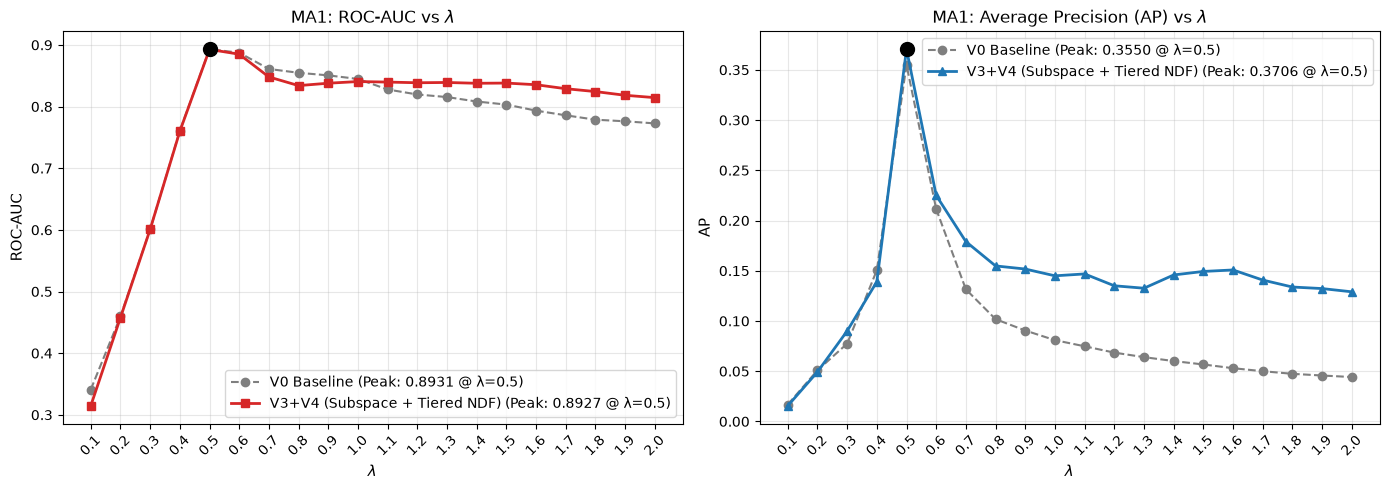

In [54]:
### Cell 27
# Execute Hybrid Variant (V3+V4) on MA1
v3_4_ma1_results = execute_variant_grid_search(
    model_cls=Variant3_4_SubspaceTieredNDF,
    data=X,
    labels=y,
    X_tem=X_tem_ma1,
    subset_name="MA1",
    variant_name="V3+V4 (Subspace + Tiered NDF)",
    lambda_range=lambda_grid)


Executing Grid Search: V3+V4 (Subspace + Tiered NDF) on MA2
Evaluating 20 lambda values in [0.1 - 2.0]
lambda =  0.1 | ROC-AUC = 0.3924 | AP = 0.0074
lambda =  0.2 | ROC-AUC = 0.4291 | AP = 0.0097
lambda =  0.3 | ROC-AUC = 0.4852 | AP = 0.0147
lambda =  0.4 | ROC-AUC = 0.6340 | AP = 0.0270
lambda =  0.5 | ROC-AUC = 0.7736 | AP = 0.0384
lambda =  0.6 | ROC-AUC = 0.7763 | AP = 0.0327
lambda =  0.7 | ROC-AUC = 0.7676 | AP = 0.0312
lambda =  0.8 | ROC-AUC = 0.6721 | AP = 0.0180
lambda =  0.9 | ROC-AUC = 0.6668 | AP = 0.0172
lambda =  1.0 | ROC-AUC = 0.6673 | AP = 0.0242
lambda =  1.1 | ROC-AUC = 0.6646 | AP = 0.0295
lambda =  1.2 | ROC-AUC = 0.6622 | AP = 0.0355
lambda =  1.3 | ROC-AUC = 0.6490 | AP = 0.0328
lambda =  1.4 | ROC-AUC = 0.6526 | AP = 0.0304
lambda =  1.5 | ROC-AUC = 0.6553 | AP = 0.0589
lambda =  1.6 | ROC-AUC = 0.6527 | AP = 0.0671
lambda =  1.7 | ROC-AUC = 0.6549 | AP = 0.0782
lambda =  1.8 | ROC-AUC = 0.6524 | AP = 0.0840
lambda =  1.9 | ROC-AUC = 0.6516 | AP = 0.0729
lam

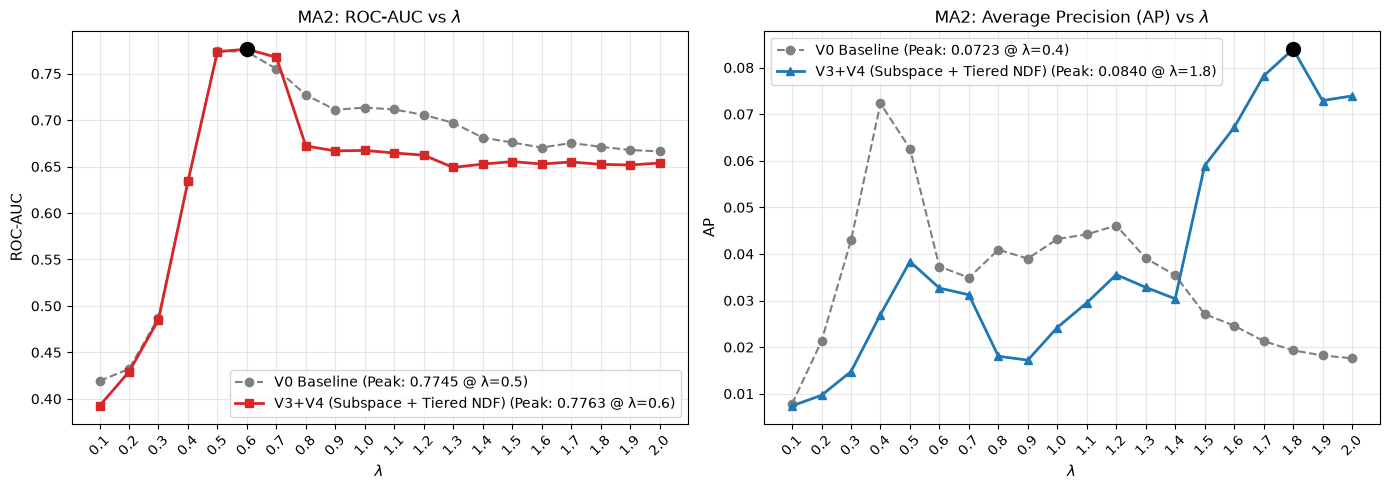

In [55]:
### Cell 28
# Execute Hybrid Variant (V3+V4) on MA2
v3_4_ma2_results = execute_variant_grid_search(
    model_cls=Variant3_4_SubspaceTieredNDF,
    data=X,
    labels=y,
    X_tem=X_tem_ma2,
    subset_name="MA2",
    variant_name="V3+V4 (Subspace + Tiered NDF)",
    lambda_range=lambda_grid)


Executing Grid Search: V3+V4 (Subspace + Tiered NDF) on MA3
Evaluating 20 lambda values in [0.1 - 2.0]
lambda =  0.1 | ROC-AUC = 0.3789 | AP = 0.0352
lambda =  0.2 | ROC-AUC = 0.5260 | AP = 0.0899
lambda =  0.3 | ROC-AUC = 0.6614 | AP = 0.1023
lambda =  0.4 | ROC-AUC = 0.7968 | AP = 0.1056
lambda =  0.5 | ROC-AUC = 0.8187 | AP = 0.1417
lambda =  0.6 | ROC-AUC = 0.7539 | AP = 0.1611
lambda =  0.7 | ROC-AUC = 0.7474 | AP = 0.0793
lambda =  0.8 | ROC-AUC = 0.7047 | AP = 0.0709
lambda =  0.9 | ROC-AUC = 0.6886 | AP = 0.0648
lambda =  1.0 | ROC-AUC = 0.6643 | AP = 0.0555
lambda =  1.1 | ROC-AUC = 0.6522 | AP = 0.0646
lambda =  1.2 | ROC-AUC = 0.6467 | AP = 0.0717
lambda =  1.3 | ROC-AUC = 0.6729 | AP = 0.0950
lambda =  1.4 | ROC-AUC = 0.6859 | AP = 0.1086
lambda =  1.5 | ROC-AUC = 0.6907 | AP = 0.1419
lambda =  1.6 | ROC-AUC = 0.6956 | AP = 0.1621
lambda =  1.7 | ROC-AUC = 0.6972 | AP = 0.1661
lambda =  1.8 | ROC-AUC = 0.6963 | AP = 0.1871
lambda =  1.9 | ROC-AUC = 0.7201 | AP = 0.2007
lam

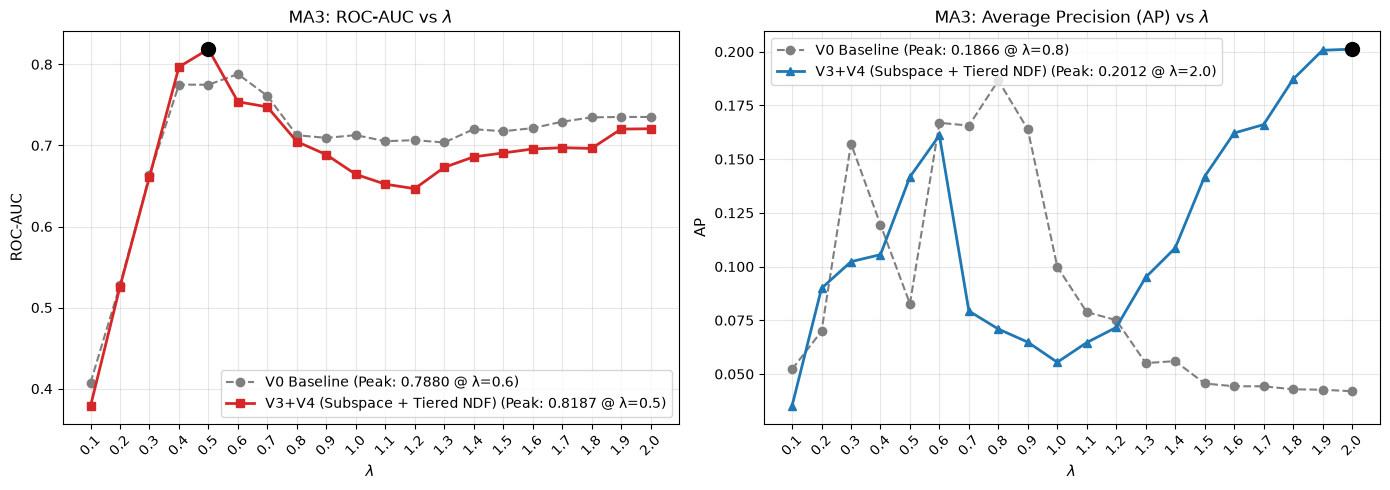

In [56]:
### Cell 29
# Execute Hybrid Variant (V3+V4) on MA3
v3_4_ma3_results = execute_variant_grid_search(
    model_cls=Variant3_4_SubspaceTieredNDF,
    data=X,
    labels=y,
    X_tem=X_tem_ma3,
    subset_name="MA3",
    variant_name="V3+V4 (Subspace + Tiered NDF)",
    lambda_range=lambda_grid)

In [57]:
### Cell 30
# Master synthesis table comparing all successful innovations against baseline V0
master_comparison = []

subsets_data = [
    ('MA1', v3_ma1_results, v4_ma1_results, v3_4_ma1_results),
    ('MA2', v3_ma2_results, v4_ma2_results, v3_4_ma2_results),
    ('MA3', v3_ma3_results, v4_ma3_results, v3_4_ma3_results)]

for name, v3_res, v4_res, v3_4_res in subsets_data:
    v0_data = BASELINE_V0_CURVES[name]
    best_v0_auc = max(v0_data, key=lambda x: x['ROC-AUC'])
    best_v0_ap = max(v0_data, key=lambda x: x['AP'])
    
    best_v3_auc = max(v3_res, key=lambda x: x['ROC-AUC'])
    best_v3_ap = max(v3_res, key=lambda x: x['AP'])
    
    best_v4_auc = max(v4_res, key=lambda x: x['ROC-AUC'])
    best_v4_ap = max(v4_res, key=lambda x: x['AP'])
    
    best_v3_4_auc = max(v3_4_res, key=lambda x: x['ROC-AUC'])
    best_v3_4_ap = max(v3_4_res, key=lambda x: x['AP'])
    
    master_comparison.append({
        "Dataset": name,
        "V0 Best (AUC | AP)": f"{best_v0_auc['ROC-AUC']:.4f} (@{best_v0_auc['lambda']}) | {best_v0_ap['AP']:.4f} (@{best_v0_ap['lambda']})",
        "V3 Subspace (AUC | AP)": f"{best_v3_auc['ROC-AUC']:.4f} (@{best_v3_auc['lambda']}) | {best_v3_ap['AP']:.4f} (@{best_v3_ap['lambda']})",
        "V4 Tiered (AUC | AP)": f"{best_v4_auc['ROC-AUC']:.4f} (@{best_v4_auc['lambda']}) | {best_v4_ap['AP']:.4f} (@{best_v4_ap['lambda']})",
        "V3+V4 Hybrid (AUC | AP)": f"{best_v3_4_auc['ROC-AUC']:.4f} (@{best_v3_4_auc['lambda']}) | {best_v3_4_ap['AP']:.4f} (@{best_v3_4_ap['lambda']})",
        "Net Gain vs V0": f"AUC: {(best_v3_4_auc['ROC-AUC'] - best_v0_auc['ROC-AUC']):+.4f} | AP: {(best_v3_4_ap['AP'] - best_v0_ap['AP']):+.4f}"})

print("\n" + "="*95)
print("MASTER EVALUATION BENCHMARK: BASELINE vs ISOLATED VARIANTS vs HYBRID MODEL")
print("="*95)
display(pd.DataFrame(master_comparison))


MASTER EVALUATION BENCHMARK: BASELINE vs ISOLATED VARIANTS vs HYBRID MODEL


,Dataset,V0 Best (AUC | AP),V3 Subspace (AUC | AP),V4 Tiered (AUC | AP),V3+V4 Hybrid (AUC | AP),Net Gain vs V0
0,MA1,0.8931 (@0.5) | 0.3550 (@0.5),0.8927 (@0.5) | 0.3718 (@0.5),0.8928 (@0.5) | 0.3556 (@0.5),0.8927 (@0.5) | 0.3706 (@0.5),AUC: -0.0004 | AP: +0.0156
1,MA2,0.7745 (@0.5) | 0.0723 (@0.4),0.7382 (@0.5) | 0.0988 (@1.3),0.7888 (@0.6) | 0.0698 (@0.5),0.7763 (@0.6) | 0.0840 (@1.8),AUC: +0.0018 | AP: +0.0117
2,MA3,0.7880 (@0.6) | 0.1866 (@0.8),0.7782 (@0.6) | 0.3092 (@1.3),0.8274 (@0.5) | 0.1715 (@0.3),0.8187 (@0.5) | 0.2012 (@2.0),AUC: +0.0307 | AP: +0.0146


#### ⚪ 

In [ ]:
.